# Análisis exploratorio de MiBici: demanda de bicicletas por zona y hora

**Equipo 9 · Exploración y preprocesamiento de datos**

El objetivo de este análisis es identificar los patrones de uso y las condiciones de calidad que deben considerarse para pronosticar la demanda de bicicletas por zona y hora. Se estudian **7,894,097 registros de viaje correspondientes a 21 meses, de enero de 2025 a septiembre de 2026**, junto con el catálogo de estaciones de septiembre de 2026.

La exploración relaciona la actividad temporal y territorial del servicio con las decisiones de preparación de datos. Examina la integridad de los registros, la plausibilidad de las duraciones y los desplazamientos, y el efecto de los criterios de limpieza sobre el conteo de viajes. Los umbrales se evalúan mediante escenarios de sensibilidad y se distinguen las conclusiones respaldadas por los datos de las hipótesis que requieren información operativa.

Las tablas de conteos abarcan la totalidad de los registros. Las visualizaciones basadas en muestras indican su alcance y utilizan ponderaciones por mes. Los datos originales se conservan sin modificaciones.

El documento se organiza en nueve apartados: contexto de negocio; fuentes y cobertura; calidad; duración y desplazamiento; patrones temporales; distribución territorial; evaluación de limpieza; preprocesamiento; y síntesis de resultados y trazabilidad.

## 1. Contexto de negocio y definición de demanda

El proyecto busca **pronosticar la demanda de bicicletas por zona y por hora** para apoyar la planeación del servicio. Conocer la distribución esperada de los viajes puede contribuir a anticipar necesidades de bicicletas, organizar recursos de redistribución y evaluar la capacidad por zona y horario. La utilidad de estas aplicaciones depende de las restricciones operativas y de los costos asociados a cada decisión.

| Pregunta de negocio | Evidencia analizada | Aplicación operativa |
|---|---|---|
| ¿Cuándo se concentra el uso? | Perfiles por hora y día de semana | Identificar ventanas para planear personal y redistribución |
| ¿Dónde se concentran las salidas? | Participación por zona y evolución mensual | Priorizar la planeación territorial |
| ¿Cómo difieren las salidas y las llegadas? | Flujos agregados por estación y zona | Investigar necesidades de rebalanceo junto con el inventario real |
| ¿Cómo cambia la actividad a lo largo del tiempo? | Estacionalidad, cobertura y cambios de nivel | Definir variables y un esquema de evaluación temporal |
| ¿Qué registros alteran la medición de demanda? | Duplicados, tiempos y coherencia geográfica | Establecer criterios de calidad con trazabilidad |

**Variable objetivo.** La demanda se define como el número de inicios de viaje aceptados en una zona durante una hora. Representa **demanda atendida observada**: los archivos no incluyen solicitudes que no pudieron realizarse por falta de bicicletas. Tampoco contienen inventario instantáneo, trayectos GPS ni tipo de bicicleta.

**Unidad de análisis.** Cada observación para el pronóstico corresponde a una combinación **zona × hora**. Se considera un horizonte de referencia de una hora; su pertinencia operativa requiere validación con negocio. Las llegadas constituyen una señal complementaria y se contabilizan por destino y hora de finalización.

La diferencia entre salidas y llegadas describe un flujo neto, pero no determina el inventario disponible: también intervienen el inventario inicial, la redistribución y el mantenimiento. La evaluación del pronóstico deberá contemplar el error absoluto medio (MAE) por zona y hora, así como el desempeño en periodos de alta actividad. Las metas de servicio y los costos de subestimar o sobreestimar requieren una definición operativa específica.

## 2. Fuentes, estructura y cobertura de los datos

El conjunto de datos está integrado por archivos mensuales de viajes y un catálogo de estaciones. La revisión de cobertura establece el periodo efectivamente observado, la continuidad de los archivos y la disponibilidad de los campos necesarios para localizar cada evento en el tiempo y el territorio.

Cada fila representa un registro de viaje. `viaje_id` identifica el evento y `usuario_id` identifica una cuenta. Estos identificadores no representan magnitudes continuas. Los campos `origen_id` y `destino_id` se relacionan con el campo `id` del catálogo. El género y el año de nacimiento son atributos declarados y no son necesarios para contar salidas.

La duración se calcula como la diferencia entre `fin` e `inicio`. La lectura estandariza nombres, codificación y fechas sin eliminar registros; los valores que no pueden interpretarse se conservan como faltantes para su diagnóstico. Los CSV no especifican una zona horaria, por lo que el análisis utiliza la hora publicada sin realizar conversiones no sustentadas.

In [1]:
from pathlib import Path
import os, sys, importlib.util, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidatos = ([Path(os.environ['MIBICI_PROJ_ROOT'])] if os.environ.get('MIBICI_PROJ_ROOT') else [])
candidatos += [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'data/raw/viajes').is_dir() and (p/'proyecto_mlops_equipo_9/dataset.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Abra el notebook dentro del proyecto o configure MIBICI_PROJ_ROOT')
sys.path.insert(0,str(ROOT))
EDA_FILE = Path(os.environ.get('MIBICI_EDA_MODULE', str(ROOT/'proyecto_mlops_equipo_9/eda.py')))
spec = importlib.util.spec_from_file_location('mibici_eda',EDA_FILE)
eda = importlib.util.module_from_spec(spec)
spec.loader.exec_module(eda)
OUT = Path(os.environ.get('MIBICI_EDA_OUT',str(ROOT/'reports/eda_integral')))
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'figures').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':.18,'axes.titleweight':'bold','font.size':10})
pd.set_option('display.max_columns',12)
pd.set_option('display.float_format', lambda x:f'{x:,.3f}')
def figura(nombre):
    plt.tight_layout()
    plt.savefig(OUT/'figures'/f'{nombre}.png',dpi=140,bbox_inches='tight')
    plt.show()
    plt.close()
inventario, ids_cruzados = eda.inventariar()
display(inventario[['mes','filas','encoding','bytes']])
display(Markdown(f"**Cobertura encontrada:** {len(inventario)} archivos; {inventario.mes.min()} a {inventario.mes.max()}; **{inventario.filas.sum():,} filas**. IDs presentes en varios archivos: **{len(ids_cruzados):,}**."))
periodos = pd.PeriodIndex(inventario.mes.str.replace('_','-'),freq='M')
esperados = pd.period_range(periodos.min(),periodos.max(),freq='M')
display(Markdown('**Meses ausentes dentro del intervalo:** '+str(list(esperados.difference(periodos)))))

2026-10-24 10:52:42.164 | INFO     | proyecto_mlops_equipo_9.config:<module>:11 - PROJ_ROOT path is: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\Git\Proyecto_MLOPS_Equipo_9


,mes,filas,encoding,bytes
0,2025_01,380184,latin-1,32959338
1,2025_02,372529,latin-1,32304810
2,2025_03,405110,utf-8,35131572
3,2025_04,366193,utf-8,31755599
4,2025_05,395891,utf-8,34332994
5,2025_06,356611,utf-8,30924814
6,2025_07,368186,latin-1,31932339
7,2025_08,374727,utf-8,32506714
8,2025_09,376789,utf-8,32686988
9,2025_10,420064,utf-8,36442309


**Cobertura encontrada:** 21 archivos; 2025_01 a 2026_09; **7,894,097 filas**. IDs presentes en varios archivos: **0**.

**Meses ausentes dentro del intervalo:** []

In [2]:
# Una pasada mensual de diagnóstico. Se reutilizan las reglas; no se generan Parquet silver.
r = eda.explorar(inventario,ids_cruzados,muestra_por_mes=15000,semilla=9)
m = r['mensual'].set_index('mes')
d = r['diario']
s = r['muestra']
display(m[['original','dias_calendario','dias_con_registros','estaciones_origen','usuarios','p99_duracion']])
display(r['estaciones'][['id','name','latitude','longitude','dpcapacity']].head())
display(Markdown(f"El catálogo contiene **{len(r['estaciones']):,} estaciones**. Su capacidad corresponde a una instantánea y no demuestra capacidad histórica. La muestra gráfica contiene **{len(s):,} registros**; cada mes aporta hasta 15,000."))

2025_01: 380,184 filas; política actual conserva 370,915
2025_02: 372,529 filas; política actual conserva 363,530
2025_03: 405,110 filas; política actual conserva 394,765
2025_04: 366,193 filas; política actual conserva 357,088
2025_05: 395,891 filas; política actual conserva 385,864
2025_06: 356,611 filas; política actual conserva 346,867
2025_07: 368,186 filas; política actual conserva 358,424
2025_08: 374,727 filas; política actual conserva 364,639
2025_09: 376,789 filas; política actual conserva 366,582
2025_10: 420,064 filas; política actual conserva 409,509
2025_11: 380,328 filas; política actual conserva 370,215
2025_12: 335,420 filas; política actual conserva 326,431
2026_01: 357,180 filas; política actual conserva 346,639
2026_02: 333,756 filas; política actual conserva 319,064
2026_03: 376,243 filas; política actual conserva 364,823
2026_04: 351,851 filas; política actual conserva 341,741
2026_05: 315,895 filas; política actual conserva 305,107
2026_06: 355,303 filas; polític

,original,dias_calendario,dias_con_registros,estaciones_origen,usuarios,p99_duracion
mes,,,,,,
2025_01,380184,31,31,368,16885,32.567
2025_02,372529,28,28,367,17175,33.629
2025_03,405110,31,31,367,17274,33.483
2025_04,366193,30,30,367,16897,32.233
2025_05,395891,31,31,367,16953,31.967
2025_06,356611,30,30,368,16455,33.415
2025_07,368186,31,31,367,16327,32.500
2025_08,374727,31,31,367,16953,32.883
2025_09,376789,30,30,367,17229,32.983


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666,-103.349,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667,-103.366,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.668,-103.368,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.692,-103.363,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681,-103.339,11


El catálogo contiene **484 estaciones**. Su capacidad corresponde a una instantánea y no demuestra capacidad histórica. La muestra gráfica contiene **315,000 registros**; cada mes aporta hasta 15,000.

**Interpretación.** El análisis abarca los 21 archivos mensuales del periodo estudiado. La ausencia de registros en un día requiere investigar la cobertura y la operación del servicio antes de interpretarla como demanda nula. Asimismo, el número de estaciones con viajes expresa actividad observada y no equivale a un padrón de estaciones oficialmente abiertas.

Los volúmenes mensuales se normalizan por días de calendario para mantener una base de comparación consistente y evitar que la ausencia de registros eleve artificialmente el promedio diario.

## 3. Diagnóstico de calidad de los datos

La evaluación de calidad distingue los problemas que comprometen el conteo por zona y hora de aquellos que afectan únicamente atributos secundarios. Se examinan tres dimensiones: **integridad**, que comprende identificadores, fechas y duplicación; **plausibilidad**, que considera tiempo y desplazamiento; y **disponibilidad geográfica**, que verifica catálogo y coordenadas.

Un mismo registro puede presentar varias condiciones de calidad. Por ello, los conteos de indicadores **no se suman** para determinar el total de exclusiones. La bitácora de selección atribuye cada registro rechazado a su primer motivo de exclusión, según un orden definido.

La política evaluada convierte en faltantes las edades calculadas fuera del intervalo de 16 a 90 años, sin eliminar el viaje. Este intervalo constituye un criterio metodológico de revisión y no una comprobación de la edad real de las personas usuarias. Los faltantes demográficos se analizan por separado de los campos necesarios para identificar y localizar el evento.

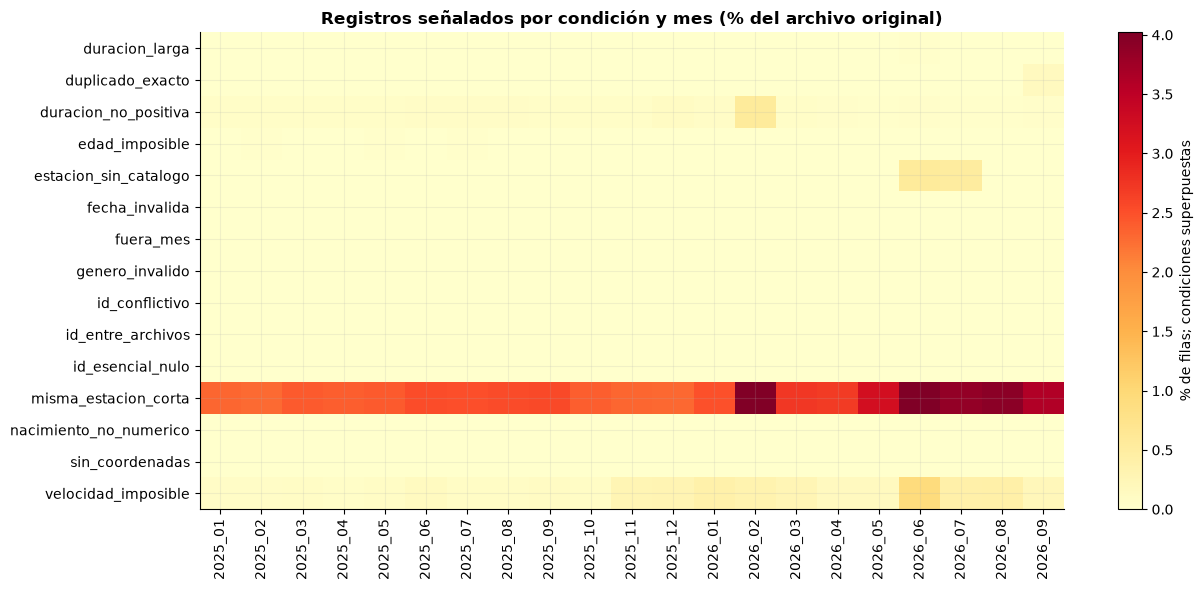

,filas,pct_original
indicador,,
flag_misma_estacion_corta,223753,2.834
flag_velocidad_imposible,17257,0.219
flag_duracion_no_positiva,5814,0.074
flag_estacion_sin_catalogo,3954,0.050
duracion_larga,854,0.011
flag_duplicado_exacto,758,0.010
flag_edad_imposible,747,0.009
flag_fuera_mes,0,0.000
flag_fecha_invalida,0,0.000


,faltantes,porcentaje
columna,,
anio_nacimiento,1436,0.018
destino_id,0,0.000
fin,0,0.000
genero,62743,0.795
inicio,0,0.000
origen_id,0,0.000
usuario_id,0,0.000
viaje_id,0,0.000


,id,apariciones_extremos,mes
0,407,2048,2026_06
1,405,6,2026_06
2,407,2029,2026_07


In [3]:
q = r['calidad'].pivot(index='indicador',columns='mes',values='porcentaje')
fig,ax=plt.subplots(figsize=(13,6))
im=ax.imshow(q,aspect='auto',cmap='YlOrRd')
ax.set_xticks(range(len(q.columns)),q.columns,rotation=90)
ax.set_yticks(range(len(q.index)),[x.replace('flag_','') for x in q.index])
ax.set_title('Registros señalados por condición y mes (% del archivo original)')
fig.colorbar(im,ax=ax,label='% de filas; condiciones superpuestas')
figura('01_calidad_mensual')
calidad_total=r['calidad'].groupby('indicador').filas.sum().to_frame()
calidad_total['pct_original']=100*calidad_total.filas/inventario.filas.sum()
display(calidad_total.sort_values('filas',ascending=False))
nulos=r['nulos'].groupby('columna').filas.sum().to_frame('faltantes')
nulos['porcentaje']=100*nulos.faltantes/inventario.filas.sum()
display(nulos)
display(r['sin_catalogo'])

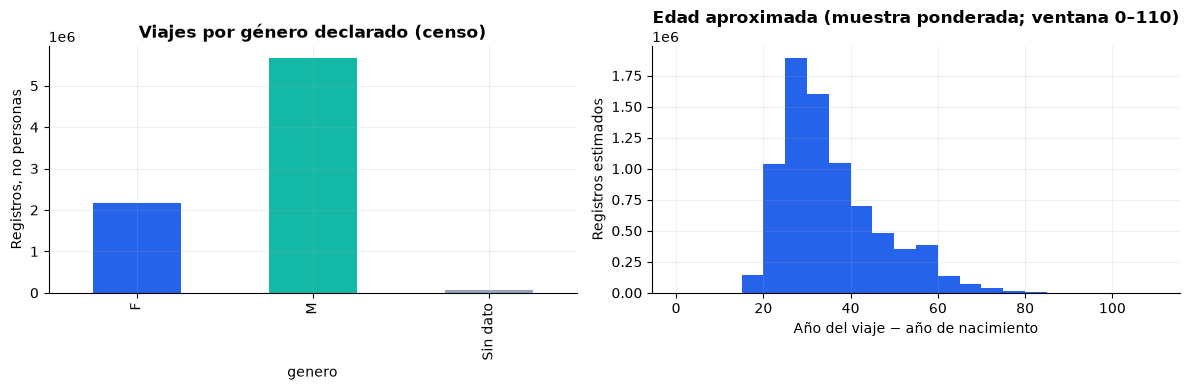

,edad_menor,edad_mayor
corte,,
15.000,398.000,"7,892,263.000"
16.000,398.000,"7,890,033.000"
18.000,"14,882.000","7,839,526.000"
80.000,"7,888,299.000","3,483.000"
90.000,"7,892,312.000",349.000
100.000,"7,892,312.000",349.000


In [4]:
genero=r['demografia'].dropna(subset=['genero']).groupby('genero').viajes.sum()
fig,axes=plt.subplots(1,2,figsize=(12,4))
genero.plot.bar(ax=axes[0],color=['#2563eb','#14b8a6','#94a3b8'][:len(genero)])
axes[0].set_title('Viajes por género declarado (censo)');axes[0].set_ylabel('Registros, no personas')
edad=s.edad_original
mask=edad.between(0,110)
axes[1].hist(edad[mask],weights=s.loc[mask,'peso'],bins=np.arange(0,115,5),color='#2563eb')
axes[1].set_title('Edad aproximada (muestra ponderada; ventana 0–110)')
axes[1].set_xlabel('Año del viaje − año de nacimiento');axes[1].set_ylabel('Registros estimados')
figura('02_demografia')
display(r['demografia'].dropna(subset=['corte']).groupby('corte')[['edad_menor','edad_mayor']].sum())

**Interpretación.** Las distribuciones demográficas representan viajes, de modo que una persona con uso frecuente aporta más registros que una persona ocasional. En consecuencia, no describen directamente la composición de la población usuaria. La edad calculada mediante la diferencia de años es aproximada.

Los viajes con información demográfica incompleta se conservan. No se imputan género ni edad para construir la demanda, y estos atributos no se incluyen como predictores iniciales. Los casos fuera de los intervalos representados en las figuras permanecen contabilizados en las tablas de calidad.

La ausencia de una estación en el catálogo de septiembre de 2026 indica que su ubicación no puede resolverse con esa fuente. No demuestra que la estación sea ficticia. Los registros asociados se mantienen identificados para permitir la recuperación y validación de su ubicación histórica.

## 4. Distribución de la duración y plausibilidad del desplazamiento

La duración se examina conjuntamente con el origen y el destino para distinguir patrones poco frecuentes de condiciones que requieren revisión. El retorno a la misma estación no invalida por sí solo un viaje, y un mínimo universal de duración podría excluir desplazamientos cortos válidos.

La velocidad implícita se calcula como la distancia Haversine entre estaciones dividida por la duración en horas. La distancia en línea recta constituye una cota inferior de la ruta recorrida; además, las coordenadas de un catálogo fijo pueden no representar ubicaciones históricas.

La política evaluada utiliza tres umbrales: **menos de 60 segundos en la misma estación, más de 30 km/h de velocidad implícita y más de 180 minutos de duración**. Estos valores son criterios configurables cuya pertinencia se examina mediante distribuciones y análisis de sensibilidad.

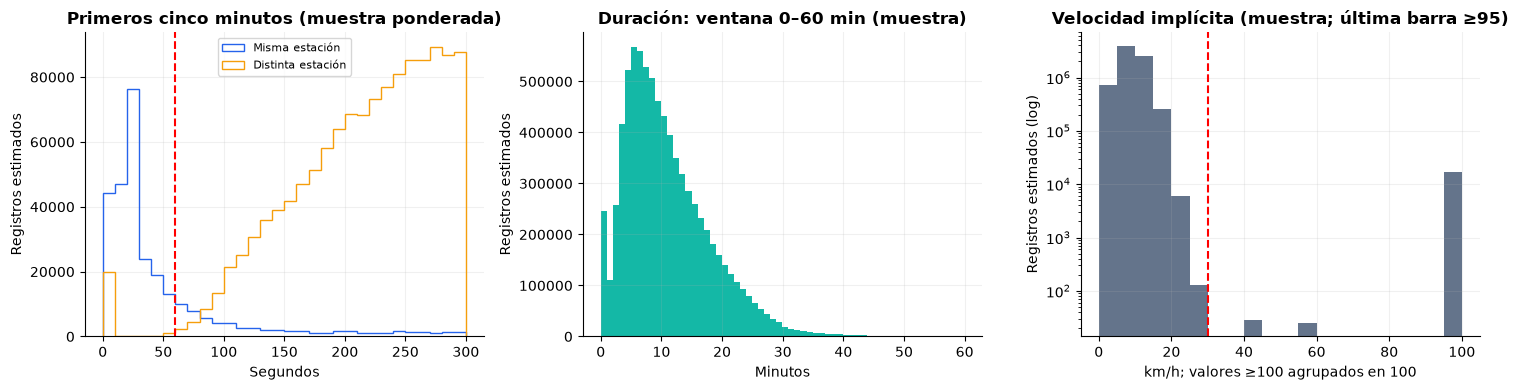

grupo,distinta,misma
intervalo_min,,
"[-inf, 0.0)",0,0
"[0.0, 1.0)",21564,223753
"[1.0, 5.0)",1248418,60293
"[10.0, 15.0)",1722639,54063
"[120.0, 180.0)",665,179
"[15.0, 30.0)",1712539,82556
"[180.0, inf)",671,183
"[30.0, 60.0)",107435,12117
"[5.0, 10.0)",2588335,53124


,mediana_duracion_original,mediana_duracion_politica,p99_duracion
mes,,,
2025_01,9.517,9.717,32.567
2025_02,9.700,9.900,33.629
2025_03,9.633,9.850,33.483
2025_04,9.500,9.700,32.233
2025_05,9.500,9.717,31.967
2025_06,9.583,9.817,33.415
2025_07,9.667,9.883,32.500
2025_08,9.633,9.867,32.883
2025_09,9.617,9.850,32.983


In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for mismo,label,color in [(True,'Misma estación','#2563eb'),(False,'Distinta estación','#f59e0b')]:
    mask=s.origen_id.eq(s.destino_id).eq(mismo)&s.duracion_min.between(0,5,inclusive='left')
    axes[0].hist(s.loc[mask,'duracion_min']*60,bins=np.arange(0,310,10),weights=s.loc[mask,'peso'],
                 histtype='step',label=label,color=color)
axes[0].axvline(60,color='red',ls='--');axes[0].legend(fontsize=8)
axes[0].set(title='Primeros cinco minutos (muestra ponderada)',xlabel='Segundos',ylabel='Registros estimados')
mask=s.duracion_min.between(0,60)
axes[1].hist(s.loc[mask,'duracion_min'],weights=s.loc[mask,'peso'],bins=60,color='#14b8a6')
axes[1].set(title='Duración: ventana 0–60 min (muestra)',xlabel='Minutos',ylabel='Registros estimados')
mask=s.origen_id.ne(s.destino_id)&s.velocidad_kmh.gt(0)&np.isfinite(s.velocidad_kmh)
axes[2].hist(s.loc[mask,'velocidad_kmh'].clip(upper=100),weights=s.loc[mask,'peso'],bins=np.arange(0,105,5),color='#64748b')
axes[2].set_yscale('log');axes[2].axvline(30,color='red',ls='--')
axes[2].set(title='Velocidad implícita (muestra; última barra ≥95)',xlabel='km/h; valores ≥100 agrupados en 100',ylabel='Registros estimados (log)')
figura('03_plausibilidad')
display(r['duraciones'].groupby(['grupo','intervalo_min']).viajes.sum().unstack('grupo'))
display(m[['mediana_duracion_original','mediana_duracion_politica','p99_duracion']])

**Interpretación.** La concentración de registros cerca de cero y las velocidades extremas identifican casos prioritarios para revisión. Por sí solas, estas características no permiten atribuirlos a mantenimiento, pruebas o intentos fallidos de uso. El análisis de sensibilidad cuantifica el efecto de modificar los umbrales.

La exclusión de viajes largos requiere especial atención porque la variable objetivo contabiliza inicios de viaje. Una devolución tardía no implica necesariamente que el inicio carezca de validez como señal de demanda. Su tratamiento exige contrastar evidencia operativa y evaluar el efecto predictivo de las alternativas con una partición temporal común.

## 5. Patrones temporales y variaciones de actividad

La exploración temporal identifica la concentración horaria y semanal del uso, las diferencias entre meses y los cambios en el nivel de actividad. Se comparan los registros originales con los aceptados por la política evaluada, utilizando promedios por día de calendario, perfiles horarios y comparaciones del mismo mes entre años.

Estas comparaciones describen variaciones observadas y no identifican sus causas. La información disponible no permite atribuir diferencias al uso de bicicletas eléctricas, al clima, a días festivos o a fallas del servicio.

<ipython-input-6-61cdf054ceec>:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dias_semana=d.fecha.dt.dayofweek.value_counts().reindex(range(7),fill_value=0)


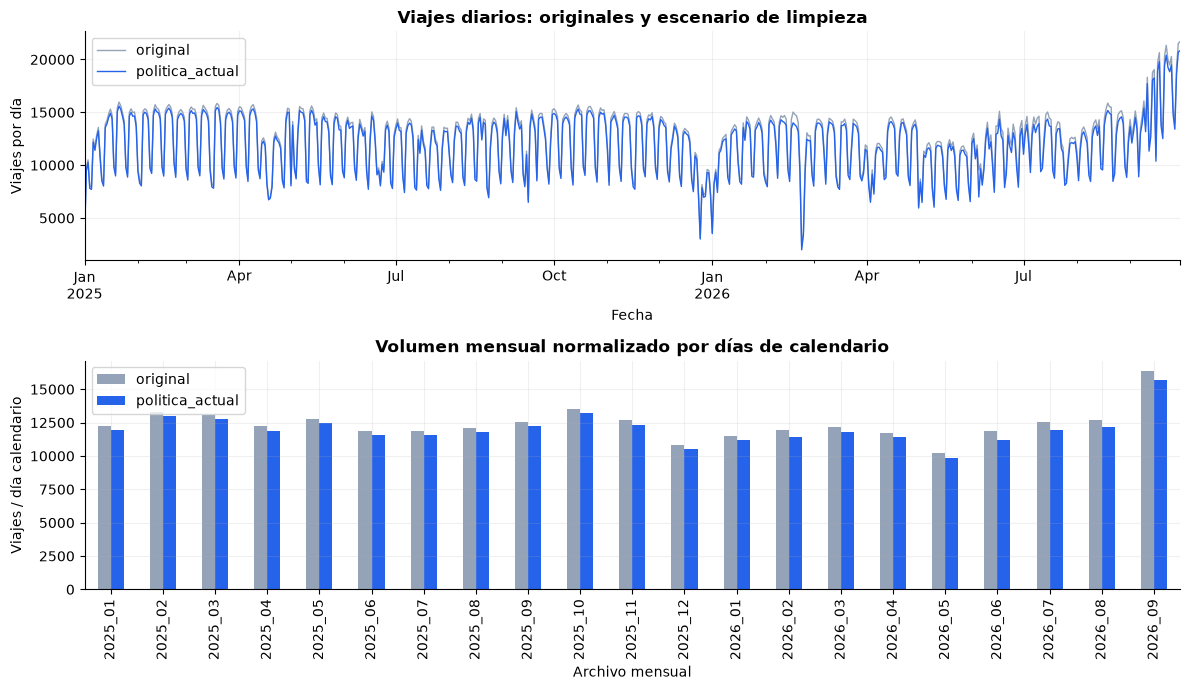

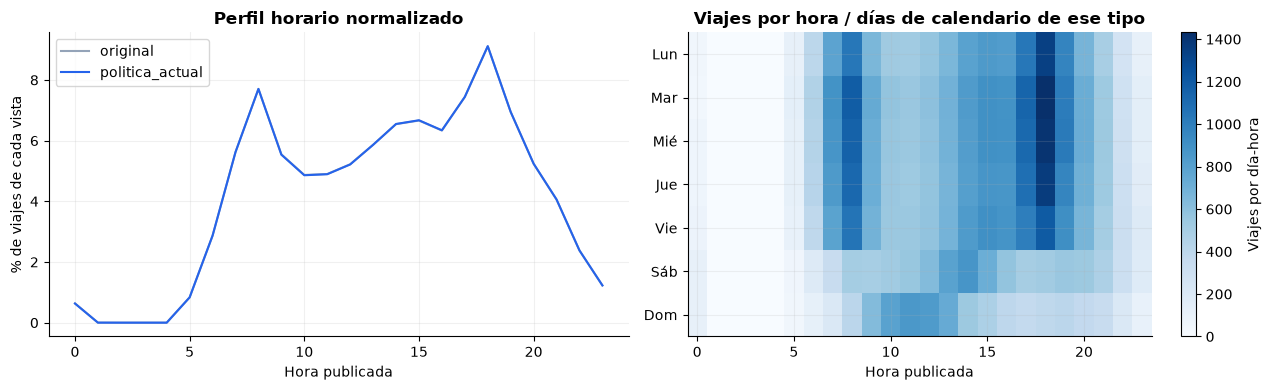

anio,2025,2026,cambio_pct_2026_vs_2025
mes_num,,,
01,"370,915.000","346,639.000",-6.545
02,"363,530.000","319,064.000",-12.232
03,"394,765.000","364,823.000",-7.585
04,"357,088.000","341,741.000",-4.298
05,"385,864.000","305,107.000",-20.929
06,"346,867.000","335,665.000",-3.229
07,"358,424.000","369,721.000",3.152
08,"364,639.000","376,340.000",3.209
09,"366,582.000","470,480.000",28.342


,fecha,original,politica_actual,ratio_mediana_dia_semana
0,2025-01-01,3404,3306,0.227
33,2025-02-03,8268,8041,0.554
75,2025-03-17,8052,7820,0.533
107,2025-04-18,6908,6721,0.523
120,2025-05-01,8256,8044,0.583
258,2025-09-16,6678,6481,0.446
320,2025-11-17,8067,7718,0.552
357,2025-12-24,7239,7034,0.543
358,2025-12-25,3113,3014,0.231
364,2025-12-31,7278,7112,0.549


In [6]:
fig,axes=plt.subplots(2,1,figsize=(12,7))
d.plot(x='fecha',y=['original','politica_actual'],ax=axes[0],color=['#94a3b8','#2563eb'],linewidth=1)
axes[0].set(title='Viajes diarios: originales y escenario de limpieza',ylabel='Viajes por día',xlabel='Fecha')
mensual=m[['original','politica_actual']].div(m.dias_calendario,axis=0)
mensual.plot.bar(ax=axes[1],color=['#94a3b8','#2563eb'])
axes[1].set(title='Volumen mensual normalizado por días de calendario',ylabel='Viajes / día calendario',xlabel='Archivo mensual')
figura('04_evolucion_temporal')

h=r['horario']
fig,axes=plt.subplots(1,2,figsize=(13,4))
for vista,color in [('original','#94a3b8'),('politica_actual','#2563eb')]:
    v=h[h.vista.eq(vista)].groupby('hora').viajes.sum()
    axes[0].plot(v.index,v/v.sum()*100,label=vista,color=color)
axes[0].set(title='Perfil horario normalizado',xlabel='Hora publicada',ylabel='% de viajes de cada vista');axes[0].legend()
hh=r['horario_dia'].query("vista == 'politica_actual'").groupby(['dia_semana','hora']).viajes.sum().unstack(fill_value=0)
dias_semana=d.fecha.dt.dayofweek.value_counts().reindex(range(7),fill_value=0)
hh=hh.div(dias_semana,axis=0).reindex(index=range(7),columns=range(24),fill_value=0)
im=axes[1].imshow(hh,aspect='auto',cmap='Blues')
axes[1].set_yticks(range(7),['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'])
axes[1].set(title='Viajes por hora / días de calendario de ese tipo',xlabel='Hora publicada')
fig.colorbar(im,ax=axes[1],label='Viajes por día-hora')
figura('05_semana_hora')

compar=m[['original','politica_actual']].copy()
compar['anio']=compar.index.str[:4];compar['mes_num']=compar.index.str[-2:]
yoy=compar.pivot(index='mes_num',columns='anio',values='politica_actual')
if {'2025','2026'}.issubset(yoy.columns):
    yoy['cambio_pct_2026_vs_2025']=(yoy['2026']/yoy['2025']-1)*100
display(yoy)
display(d[d.dia_bajo_por_investigar][['fecha','original','politica_actual','ratio_mediana_dia_semana']])

**Interpretación.** Las diferencias por hora y día de semana respaldan la incorporación de variables de calendario. La evolución mensual y los cambios de cobertura requieren un esquema de evaluación temporal. Las comparaciones interanuales reducen algunas diferencias estacionales, pero no controlan todos los factores que podrían modificar la actividad.

Se señalan para investigación los días con un volumen inferior al 60% de la mediana del mismo día de semana dentro de su mes. Este indicador es retrospectivo: no identifica fallas ni determina exclusiones automáticas. Tampoco está disponible como predictor antes de observar el mes completo. Su interpretación requiere contrastar el calendario y los registros operativos.

## 6. Distribución territorial y agregación por zona

La agregación territorial permite estudiar la concentración de salidas y las diferencias de perfil horario entre zonas. Para este análisis se utiliza una **cuadrícula exploratoria fija de 1 km**, construida mediante una proyección local aproximada. Los insumos no contienen polígonos de zonas operativas; por tanto, la cuadrícula no representa colonias ni una zonificación aprobada por negocio.

Los identificadores geográficos son reproducibles y no se ajustan al volumen de viajes. Se comparan celdas de 500, 1,000 y 1,500 metros para evaluar el efecto de la granularidad. Una mayor superficie agrega más estaciones y puede estabilizar los conteos, aunque reduce el detalle disponible para la redistribución. La elección definitiva requiere criterios operativos y validación temporal.

,salidas,llegadas,saldo_salidas_llegadas,participacion_pct
zona,,,,
G1000_-10753_2299,"712,495.000","726,225.000","-13,730.000",9.320
G1000_-10753_2298,"613,647.000","673,434.000","-59,787.000",8.027
G1000_-10754_2298,"573,906.000","557,367.000","16,539.000",7.508
G1000_-10755_2298,"429,639.000","389,734.000","39,905.000",5.620
G1000_-10755_2299,"428,624.000","394,312.000","34,312.000",5.607
G1000_-10754_2299,"421,173.000","400,704.000","20,469.000",5.510
G1000_-10753_2300,"386,669.000","376,139.000","10,530.000",5.058
G1000_-10752_2298,"329,648.000","391,039.000","-61,391.000",4.312
G1000_-10756_2298,"318,763.000","231,738.000","87,025.000",4.170


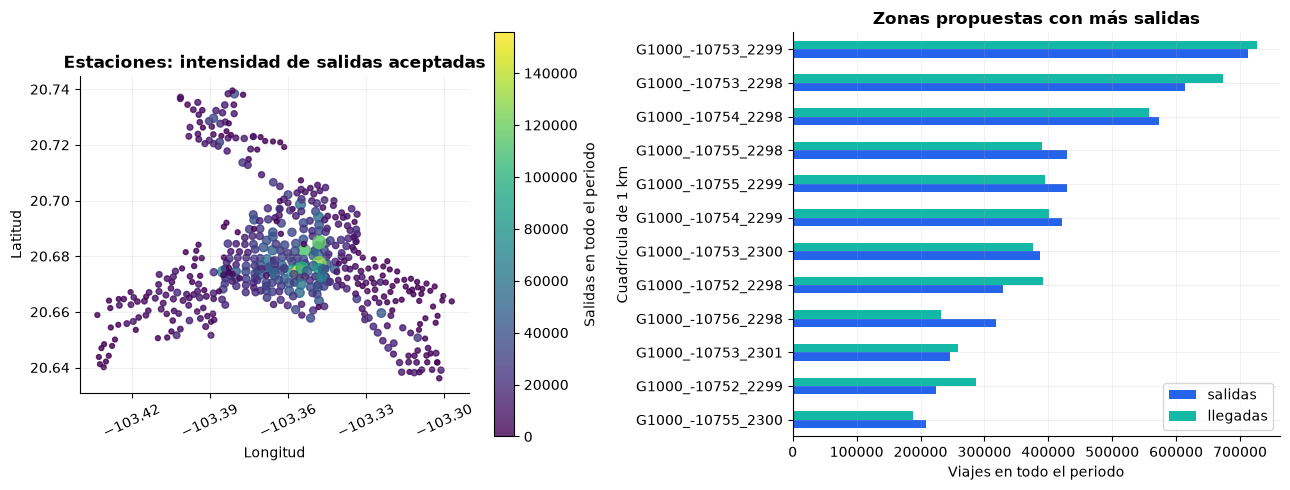

,celda_m,zonas_con_salidas,mediana_salidas_por_zona,pct_salidas_5_zonas_mayores
0,500,223,"15,644.000",14.974
1,1000,80,"41,959.000",36.083
2,1500,46,"52,108.500",58.447


,estaciones_observadas_por_primera_vez
primera_observacion,
2025-01,368
2025-06,1
2025-10,1
2025-12,1
2026-05,12
2026-06,43
2026-07,31
2026-08,15


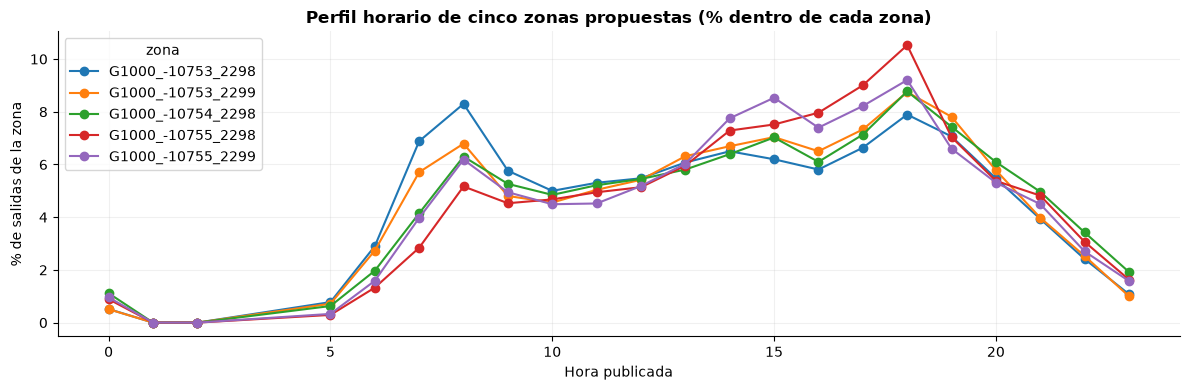

In [7]:
est=r['estacion'].query("vista == 'politica_actual'").groupby('id')[['salidas','llegadas']].sum()
geo=r['zonas'].merge(est,on='id',how='left')
geo[['salidas','llegadas']]=geo[['salidas','llegadas']].fillna(0)
geo['saldo_salidas_llegadas']=geo.salidas-geo.llegadas
zonas=geo.groupby('zona')[['salidas','llegadas']].sum()
zonas['saldo_salidas_llegadas']=zonas.salidas-zonas.llegadas
zonas['participacion_pct']=100*zonas.salidas/zonas.salidas.sum()
display(zonas.sort_values('salidas',ascending=False).head(15))
fig,axes=plt.subplots(1,2,figsize=(13,5))
plot=geo.dropna(subset=['zona'])
sc=axes[0].scatter(plot.longitude,plot.latitude,s=12+100*plot.salidas/plot.salidas.max(),c=plot.salidas,cmap='viridis',alpha=.8)
axes[0].set(title='Estaciones: intensidad de salidas aceptadas',xlabel='Longitud',ylabel='Latitud')
axes[0].set_aspect(1/np.cos(np.radians(20.67)))
from matplotlib.ticker import MaxNLocator
axes[0].xaxis.set_major_locator(MaxNLocator(5))
axes[0].tick_params(axis='x',labelrotation=25)
fig.colorbar(sc,ax=axes[0],label='Salidas en todo el periodo')
top=zonas.nlargest(12,'salidas').sort_values('salidas')
top[['salidas','llegadas']].plot.barh(ax=axes[1],color=['#2563eb','#14b8a6'])
axes[1].set(title='Zonas propuestas con más salidas',xlabel='Viajes en todo el periodo',ylabel='Cuadrícula de 1 km')
figura('06_territorio_zonas')

granularidad=[]
for celda in [500,1000,1500]:
    z=eda.zonificar(r['estaciones'],celda).merge(est,on='id',how='left')
    counts=z.groupby('zona').salidas.sum()
    counts=counts[counts.gt(0)]
    granularidad.append({'celda_m':celda,'zonas_con_salidas':len(counts),
                         'mediana_salidas_por_zona':counts.median(),
                         'pct_salidas_5_zonas_mayores':100*counts.nlargest(5).sum()/counts.sum()})
display(pd.DataFrame(granularidad))

primera=r['primer_uso'].groupby('id').primera_observacion.min()
primera=pd.to_datetime(primera)
display(primera.groupby(primera.dt.to_period('M')).size().rename('estaciones_observadas_por_primera_vez').to_frame())
zh=r['zona_hora'].query("vista == 'politica_actual'")
zonas_top=zonas.nlargest(5,'salidas').index
perfil=zh[zh.zona.isin(zonas_top)].groupby(['hora','zona']).salidas.sum().unstack(fill_value=0)
perfil.div(perfil.sum(),axis=1).mul(100).plot(marker='o',figsize=(12,4))
plt.title('Perfil horario de cinco zonas propuestas (% dentro de cada zona)')
plt.ylabel('% de salidas de la zona');plt.xlabel('Hora publicada')
figura('07_perfiles_zonales')

**Interpretación.** La zonificación utiliza estaciones con coordenadas válidas. La primera aparición de una estación en los archivos corresponde a su primera observación dentro del periodo analizado y no a su fecha de inauguración. Para las estaciones presentes al inicio de la serie, su actividad anterior queda fuera del alcance de los datos.

Las diferencias entre salidas y llegadas permiten identificar desequilibrios de flujo que ameritan evaluación operativa. Sin embargo, no determinan la cantidad de bicicletas que debe redistribuirse. El catálogo fijo también limita las comparaciones históricas: la capacidad publicada en septiembre de 2026 no se utiliza para inferir la utilización de estaciones en periodos anteriores.

La adopción de zonas para el pronóstico requiere validar su utilidad operativa y resolver las ubicaciones históricas pendientes.

## 7. Evaluación y fundamento de las decisiones de limpieza

El efecto de la limpieza se examina mediante tres vistas del conjunto de datos: **original**, que conserva todos los registros; **integridad**, que aplica criterios de identificación, coherencia temporal y deduplicación; y **política actual**, que incorpora además disponibilidad de catálogo, coordenadas y umbrales de plausibilidad.

La comparación permite distinguir las exclusiones necesarias para cumplir el contrato de datos de aquellas que dependen de decisiones metodológicas sobre el uso esperado del servicio. La bitácora registra el primer motivo de exclusión de cada fila y permite verificar el balance entre registros originales, aceptados y excluidos.

El análisis de sensibilidad modifica un parámetro a la vez en los **21 meses**, manteniendo constantes las demás reglas. La cantidad de registros retenidos se interpreta como efecto sobre la señal de demanda, no como una medida directa de calidad o precisión predictiva.

,original,integridad,politica_actual,exclusion_pct
mes,,,,
2025_01,380184,379979,370915,2.438
2025_02,372529,372335,363530,2.416
2025_03,405110,404894,394765,2.554
2025_04,366193,366008,357088,2.486
2025_05,395891,395702,385864,2.533
2025_06,356611,356333,346867,2.732
2025_07,368186,367933,358424,2.651
2025_08,374727,374452,364639,2.692
2025_09,376789,376561,366582,2.709


,orden,paso,filas_excluidas
0,1,id_esencial_nulo,0
1,2,fecha_invalida,0
2,3,inicio_fuera_mes,0
3,4,id_conflictivo,0
4,5,id_entre_archivos,0
5,6,duplicado_exacto,758
6,7,duracion_no_positiva,5814
7,8,misma_estacion_corta,221119
8,9,estacion_sin_catalogo,3888
9,10,sin_coordenadas,0


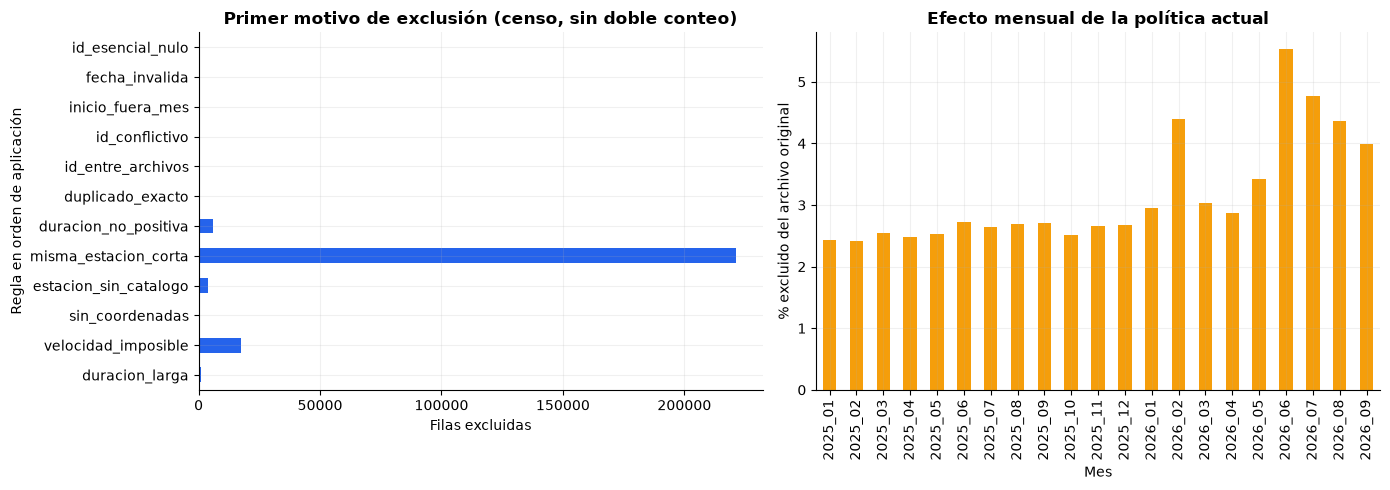

retenidos  diferencia_vs_actual
factor           umbral                                 
duracion_min     120       7643566                  -843
                 180       7644409                     0
                 240       7644731                   322
misma_estacion_s 30        7701335                 56926
                 60        7644409                     0
                 90        7621361                -23048
velocidad_kmh    25        7644314                   -95
                 30        7644409                     0
                 40        7644454                    45
                 60        7644499                    90

factor  duracion_min              misma_estacion_s                   \
umbral           120   180    240              30    60         90    
mes                                                                   
2025_01      -26.000 0.000 27.000        1,811.000 0.000   -674.000   
2025_02      -46.000 0.000 17.000        1,832.000 0.000   -698.000   
2025_03      -31.000 0.000 20.000        2,104.000 0.000   -840.000   
2025_04      -24.000 0.000  3.000        1,984.000 0.000   -769.000   
2025_05      -39.000 0.000 14.000        2,152.000 0.000   -829.000   
2025_06      -34.000 0.000 20.000        2,021.000 0.000   -774.000   
2025_07      -39.000 0.000 12.000        2,058.000 0.000   -819.000   
2025_08      -38.000 0.000  8.000        2,149.000 0.000   -881.000   
2025_09      -41.000 0.000 14.000        2,205.000 0.000   -873.000   
2025_10      -31.000 0.000 13.000        2,322.000 0.000   -982.000   
2025_11      -41.000 0.000 16.000        2,190.000 0.000   -875.000   
2025_12      -41.000 0.000 17.000        1,794.000 0.000   -702.000   
2026_01      -26.000 0.000 15.000        2,242.000 0.000   -890.000   
2026_02      -36.000 0.000 19.000        2,103.000 0.000   -897.000   
2026_03      -28.000 0.000 15.000        2,903.000 0.000 -1,098.000   
2026_04      -42.000 0.000 11.000        2,885.000 0.000 -1,136.000   
2026_05      -31.000 0.000 13.000        3,362.000 0.000 -1,353.000   
2026_06      -65.000 0.000 18.000        4,183.000 0.000 -1,782.000   
2026_07      -48.000 0.000 27.000        4,674.000 0.000 -2,040.000   
2026_08      -78.000 0.000 12.000        4,620.000 0.000 -1,939.000   
2026_09      -58.000 0.000 11.000        5,332.000 0.000 -2,197.000   

factor  velocidad_kmh                      
umbral            25    30     40     60   
mes                                        
2025_01        -6.000 0.000  1.000  3.000  
2025_02         0.000 0.000  0.000  0.000  
2025_03        -4.000 0.000  0.000  1.000  
2025_04        -5.000 0.000  0.000  0.000  
2025_05        -1.000 0.000  0.000  0.000  
2025_06        -2.000 0.000  0.000  0.000  
2025_07        -3.000 0.000  0.000  0.000  
2025_08        -3.000 0.000  0.000  0.000  
2025_09       -10.000 0.000  8.000 26.000  
2025_10       -17.000 0.000 15.000 27.000  
2025_11       -11.000 0.000 14.000 25.000  
2025_12         0.000 0.000  0.000  0.000  
2026_01        -1.000 0.000  0.000  0.000  
2026_02         0.000 0.000  0.000  0.000  
2026_03        -2.000 0.000  0.000  0.000  
2026_04        -4.000 0.000  0.000  0.000  
2026_05        -2.000 0.000  0.000  0.000  
2026_06        -5.000 0.000  3.000  3.000  
2026_07       -11.000 0.000  0.000  1.000  
2026_08        -5.000 0.000  1.000  1.000  
2026_09        -3.000 0.000  3.000  3.000

**Decisión prioritaria:** `misma_estacion_corta` explica **221,119** exclusiones, el **88.6%** del total excluido. Conviene validar primero esta regla con operación: es la que más modifica la señal de demanda.

,original,politica_actual,excluidos,exclusion_pct
id,,,,
51,"161,975.000","155,720.000","6,255.000",3.862
50,"96,467.000","92,293.000","4,174.000",4.327
11,"115,317.000","111,471.000","3,846.000",3.335
54,"88,626.000","85,094.000","3,532.000",3.985
271,"120,327.000","116,883.000","3,444.000",2.862
194,"82,698.000","79,334.000","3,364.000",4.068
75,"64,912.000","61,621.000","3,291.000",5.070
35,"129,786.000","126,842.000","2,944.000",2.268
52,"99,306.000","96,536.000","2,770.000",2.789


vista,original,politica_actual,exclusion_pct
zona,,,
G1000_-10749_2298,"5,698.000","5,349.000",6.125
G1000_-10761_2295,"1,801.000","1,709.000",5.108
G1000_-10748_2298,"1,968.000","1,869.000",5.030
G1000_-10748_2297,"2,482.000","2,358.000",4.996
G1000_-10757_2299,"4,066.000","3,868.000",4.870
G1000_-10748_2296,"1,376.000","1,309.000",4.869
G1000_-10761_2296,"1,380.000","1,318.000",4.493
G1000_-10761_2297,"9,959.000","9,529.000",4.318
G1000_-10757_2296,"23,344.000","22,343.000",4.288


In [8]:
display(m[['original','integridad','politica_actual','exclusion_pct']])
bit=r['bitacora'].groupby(['orden','paso']).filas_excluidas.sum().reset_index().sort_values('orden')
display(bit)
fig,axes=plt.subplots(1,2,figsize=(14,5))
bit.set_index('paso').filas_excluidas.plot.barh(ax=axes[0],color='#2563eb')
axes[0].invert_yaxis();axes[0].set(title='Primer motivo de exclusión (censo, sin doble conteo)',xlabel='Filas excluidas',ylabel='Regla en orden de aplicación')
m.exclusion_pct.plot.bar(ax=axes[1],color='#f59e0b')
axes[1].set(title='Efecto mensual de la política actual',ylabel='% excluido del archivo original',xlabel='Mes')
figura('08_impacto_limpieza')

sens=r['sensibilidad'].groupby(['factor','umbral'])[['retenidos','diferencia_vs_actual']].sum()
display(sens)
display(r['sensibilidad'].pivot_table(index='mes',columns=['factor','umbral'],values='diferencia_vs_actual'))
top_regla=bit.loc[bit.filas_excluidas.idxmax()]
display(Markdown(f"**Decisión prioritaria:** `{top_regla.paso}` explica **{int(top_regla.filas_excluidas):,}** exclusiones, el **{100*top_regla.filas_excluidas/bit.filas_excluidas.sum():.1f}%** del total excluido. Conviene validar primero esta regla con operación: es la que más modifica la señal de demanda."))

orig=r['estacion'].query("vista == 'original'").groupby('id').salidas.sum()
fin=r['estacion'].query("vista == 'politica_actual'").groupby('id').salidas.sum()
impacto=pd.concat([orig.rename('original'),fin.rename('politica_actual')],axis=1).fillna(0)
impacto['excluidos']=impacto.original-impacto.politica_actual
impacto['exclusion_pct']=100*impacto.excluidos/impacto.original.replace(0,np.nan)
display(impacto.nlargest(15,'excluidos'))
impacto.reset_index().to_csv(OUT/'impacto_por_estacion.csv',index=False)
zi=r['estacion'].merge(r['zonas'][['id','zona']],on='id',how='left')
zi=zi.groupby(['zona','vista']).salidas.sum().unstack(fill_value=0)
zi['exclusion_pct']=100*(1-zi.politica_actual/zi.original.replace(0,np.nan))
display(zi.sort_values('exclusion_pct',ascending=False).head(15))
zi.to_csv(OUT/'impacto_por_zona.csv')

**Matriz de decisiones de limpieza.** Los criterios se clasifican según su fundamento en el contrato de datos, la evidencia observada y la necesidad de validación operativa.

| Condición | Evidencia disponible | Tratamiento propuesto y fundamento | Estado |
|---|---|---|---|
| Copias exactas | Conteos censales y bitácora | Conservar una copia; un mismo evento no debe inflar el objetivo | Sustentado por unicidad |
| ID con datos distintos o compartido entre archivos | Diagnóstico de identificadores | Cuarentena e investigación, sin elegir arbitrariamente una versión | Revisar fuente |
| Fechas/IDs esenciales inválidos | Conteos y cobertura | Cuarentena según la vista requerida; sin inicio no se puede ubicar la salida en una hora | Sustentado por contrato |
| Inicio fuera del mes del archivo | Comparación de inicio con partición | Investigar/reubicar con trazabilidad; la discrepancia no prueba duplicación | Revisar fuente |
| Duración no positiva | Cálculo `fin − inicio` | Marcar/cuarentena en vista de viajes completos; revisar definición si negocio cuenta intentos | Contrato propuesto |
| Misma estación y <60 s | Histograma y sensibilidad 30/60/90 s | Posible intento fallido; exclusión configurable, causa no confirmada | Validar con operación |
| Velocidad implícita >30 km/h | Coordenadas, duración y sensibilidad 25/30/40/60 | Señalar incoherencia; revisar catálogo y tipo de bici antes de aceptar el corte | Validar con operación |
| Duración >180 min | Cola y sensibilidad 120/180/240 min | Revisar exclusión: un inicio puede representar demanda aunque la devolución sea tardía | Decisión abierta |
| Estación sin catálogo/coordenadas | IDs y volumen afectados | Conservar en auditoría; no asignar zona inventada. Recuperar catálogo histórico | Pendiente geográfico |
| Estación marcada `ex-` | Instantánea actual | Conservar viajes históricos válidos; el estado actual no invalida el pasado | Conservar |
| Edad/género faltantes o fuera de rango | Nulos, valores y sensibilidad etaria | No eliminar viajes; marcar atributo, preservar original; no usarlos como predictores iniciales | Conservar evento |
| Día de volumen bajo | Comparación retrospectiva por día de semana | Investigar calendario/cobertura; no eliminar automáticamente | Validar causa |

**Implicación para negocio:** una regla puede cambiar niveles, perfiles horarios y participación por zona. Los porcentajes por mes, estación y zona permiten detectar impactos desiguales; todavía no prueban sesgo sobre grupos poblacionales ni mejora predictiva.

## 8. Preprocesamiento para el pronóstico por zona y hora

El preprocesamiento transforma registros de viaje en observaciones temporales aptas para el pronóstico. Su diseño conserva la interpretación del objetivo y evita incorporar información que no estaría disponible en el momento de emitir una predicción.

1. **Agregación de eventos.** Las salidas se cuentan por zona de origen y hora de inicio. Las llegadas se contabilizan por zona de destino y hora de finalización.
2. **Calendario horario.** Se establece una secuencia completa de horas. La ausencia de registros se mantiene identificada hasta verificar horarios de operación, cobertura y disponibilidad de estaciones; no se interpreta automáticamente como demanda cero.
3. **Variables predictoras.** Se representan la hora de forma cíclica y el día de semana como categoría. Los rezagos y promedios móviles se construyen exclusivamente con observaciones anteriores a la hora objetivo.
4. **Separación temporal.** El entrenamiento precede cronológicamente a la validación y la prueba. Los transformadores se ajustan únicamente con entrenamiento y se aplican sin reajuste a las particiones posteriores.
5. **Codificación y escala.** Las variables de calendario y zona se codifican como categorías; los identificadores no se tratan como cantidades continuas. Los rezagos pueden estandarizarse para modelos sensibles a la escala. Las variables cíclicas ya están acotadas. No se aplica reducción de dimensionalidad sin evidencia de una necesidad que compense la pérdida de interpretabilidad.

**Aplicación ilustrativa.** El procedimiento se muestra con una zona durante una semana de mayo de 2026. Las horas sin conteos permanecen como faltantes. La división temporal 60/20/20 permite comprobar el ajuste del preprocesador exclusivamente con entrenamiento y no constituye la partición definitiva para evaluar un modelo.

In [9]:
MES_DEMO='2026_05' if '2026_05' in inventario.mes.values else inventario.mes.iloc[-1]
por_zona=r['zona_hora'].query("vista == 'politica_actual' and mes == @MES_DEMO").groupby('zona').salidas.sum()
ZONA_DEMO=por_zona.idxmax()
inicio=pd.Timestamp(MES_DEMO.replace('_','-')+'-01')
panel=eda.panel_horario(r,ZONA_DEMO,inicio,inicio+pd.Timedelta(days=7))
display(panel.head(30))
display(panel.groupby('particion').agg(horas=('fecha_hora','size'),sin_salidas_registradas=('sin_salidas_registradas','sum')))
panel.to_csv(OUT/'demostracion_panel_zona_hora.csv',index=False)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
preparador=ColumnTransformer([
    ('rezago_escalado',StandardScaler(),['salidas_lag_24h']),
    ('calendario',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['dia_semana']),
    ('hora_ciclica','passthrough',['hora_sin','hora_cos'])
])
features=['salidas_lag_24h','dia_semana','hora_sin','hora_cos']
train=panel.particion.eq('entrenamiento')
X_train=preparador.fit_transform(panel.loc[train,features])
X_valid=preparador.transform(panel.loc[panel.particion.eq('validacion'),features])
display(pd.DataFrame({'variable_transformada':preparador.get_feature_names_out()}))
display(Markdown(f"Demostración: **{train.sum()} horas** para ajustar el preprocesador y **{len(X_valid)}** de validación solo transformadas. Los NaN de rezagos permanecen: no se entrenó un modelo ni se imputaron ceros."))

,fecha_hora,zona,salidas_observadas,llegadas_observadas,sin_salidas_registradas,hora_sin,hora_cos,dia_semana,salidas_lag_24h,media_previa_24h,particion
0,2026-05-01 00:00:00,G1000_-10753_2299,9.000,4.000,False,0.000,1.000,4,<NA>,NaN,entrenamiento
1,2026-05-01 01:00:00,G1000_-10753_2299,<NA>,1.000,True,0.259,0.966,4,<NA>,NaN,entrenamiento
2,2026-05-01 02:00:00,G1000_-10753_2299,<NA>,<NA>,True,0.500,0.866,4,<NA>,NaN,entrenamiento
3,2026-05-01 03:00:00,G1000_-10753_2299,<NA>,<NA>,True,0.707,0.707,4,<NA>,NaN,entrenamiento
4,2026-05-01 04:00:00,G1000_-10753_2299,<NA>,<NA>,True,0.866,0.500,4,<NA>,NaN,entrenamiento
5,2026-05-01 05:00:00,G1000_-10753_2299,2.000,3.000,False,0.966,0.259,4,<NA>,NaN,entrenamiento
6,2026-05-01 06:00:00,G1000_-10753_2299,14.000,10.000,False,1.000,0.000,4,<NA>,NaN,entrenamiento
7,2026-05-01 07:00:00,G1000_-10753_2299,16.000,16.000,False,0.966,-0.259,4,<NA>,NaN,entrenamiento
8,2026-05-01 08:00:00,G1000_-10753_2299,27.000,26.000,False,0.866,-0.500,4,<NA>,NaN,entrenamiento
9,2026-05-01 09:00:00,G1000_-10753_2299,41.000,24.000,False,0.707,-0.707,4,<NA>,NaN,entrenamiento


,horas,sin_salidas_registradas
particion,,
entrenamiento,101,20
prueba,33,3
validacion,34,4


,variable_transformada
0,rezago_escalado__salidas_lag_24h
1,calendario__dia_semana_0
2,calendario__dia_semana_1
3,calendario__dia_semana_4
4,calendario__dia_semana_5
5,calendario__dia_semana_6
6,hora_ciclica__hora_sin
7,hora_ciclica__hora_cos


Demostración: **101 horas** para ajustar el preprocesador y **34** de validación solo transformadas. Los NaN de rezagos permanecen: no se entrenó un modelo ni se imputaron ceros.

**Alcance del preprocesamiento.** Los rezagos permanecen incompletos cuando no existen observaciones previas suficientes. En un pronóstico de varios pasos, las variables deben limitarse a la información disponible en el instante de emisión. Las salidas de la hora objetivo y las llegadas contemporáneas no pueden incorporarse como predictores si aún no han ocurrido.

La evaluación predictiva requiere particiones cronológicas y métricas desagregadas por zona, hora y condiciones de cobertura. Dado que el periodo completo forma parte de la exploración, no constituye una prueba ciega independiente. La evaluación de generalización deberá reservar nuevos datos o explicitar esta limitación después de fijar las decisiones metodológicas.

## 9. Síntesis de resultados y trazabilidad

Los resultados integran la cobertura de las fuentes, los patrones de uso y el efecto de la limpieza sobre la demanda observada. Su interpretación distingue las decisiones respaldadas por la evidencia de los aspectos que requieren validación operativa.

Las fuentes, el catálogo, los parámetros y el código de cálculo se identifican mediante huellas SHA-256. Los productos del análisis incluyen tablas agregadas y figuras, sin identificadores individuales de usuarios. Esta trazabilidad permite relacionar cada resultado con los insumos y criterios empleados.

In [10]:
total=int(m.original.sum());retenidos=int(m.politica_actual.sum())
hora_pico=int(h[h.vista.eq('politica_actual')].groupby('hora').viajes.sum().idxmax())
duplicados=int(calidad_total.loc['flag_duplicado_exacto','filas'])
top5_pct=float(zonas.nlargest(5,'salidas').salidas.sum()/zonas.salidas.sum()*100)
perfil_h=h[h.vista.eq('politica_actual')].groupby('hora').viajes.sum()
participacion_pico=float(100*perfil_h.loc[hora_pico]/perfil_h.sum())
medias_dow=d.groupby('dia_semana').politica_actual.mean()
ratio_fin_semana=float(medias_dow.loc[[5,6]].mean()/medias_dow.loc[range(5)].mean())
resumen=f"""### Resultados calculados

- Se analizaron **{len(m)} meses**, de **{m.index.min()} a {m.index.max()}**, con **{total:,} registros originales**.
- La política actual conserva **{retenidos:,}** y excluye **{total-retenidos:,} ({100*(1-retenidos/total):.2f}%)**. Este porcentaje evalúa el efecto de la política; no certifica que todas las exclusiones sean errores reales.
- Se identifican **{duplicados:,} copias exactas adicionales**. Los conteos de otras banderas pueden superponerse.
- La hora con más salidas aceptadas en el periodo agregado es **{hora_pico:02d}:00**. Las figuras por zona y día permiten revisar si ese patrón es compartido.
- La cuadrícula exploratoria de 1 km reúne **{int(zonas.salidas.gt(0).sum())} zonas con salidas**. Debe validarse con negocio antes de usarla como unidad definitiva.
- Hay **{int(d.dia_bajo_por_investigar.sum())} días de volumen bajo por investigar**; el diagnóstico no identifica su causa ni los elimina.

### Interpretación para negocio

- La hora de las **{hora_pico:02d}:00 concentra {participacion_pico:.1f}%** de las salidas aceptadas. Planear solo con promedios diarios ocultaría esa concentración horaria; el pronóstico debe distinguir horas y días.
- El promedio diario de sábado y domingo equivale al **{100*ratio_fin_semana:.1f}%** del promedio diario de lunes a viernes (promedio de las medias por tipo de día). El calendario debe formar parte del análisis y de las variables candidatas, sin asumir la causa del patrón.
- Las cinco zonas exploratorias de mayor actividad reúnen **{top5_pct:.1f}%** de las salidas zonificadas. Esto sugiere priorizar su evaluación operativa, conservando métricas para zonas de menor volumen para que el agregado no oculte sus errores.
- La mayor contribución a las exclusiones corresponde a **{top_regla.paso}**, con **{int(top_regla.filas_excluidas):,} registros**. Su validación tiene más efecto sobre el objetivo que ajustar reglas con pocos casos; los escenarios de sensibilidad permiten cuantificar el cambio.

### Decisiones que este EDA permite sostener

1. Construir el objetivo como conteo de salidas observadas por zona/hora, declarando que no representa demanda insatisfecha.
2. Deduplicar eventos idénticos y conservar trazabilidad de cuarentenas y transformaciones.
3. Mantener viajes con demografía incompleta; evitar filtros poblacionales para contar demanda.
4. Usar calendario y estructura temporal; contrastar cualquier limpieza con su impacto mensual y territorial.
5. Mantener abiertas la zonificación final y la aprobación operativa de umbrales de duración y velocidad.

### Lo que todavía no demuestra

No demuestra causalidad de e-bikes, causas de días bajos, inventario disponible, demanda perdida, mejora predictiva ni retorno económico. Para esos objetivos se requieren datos adicionales y evaluación específica.
"""
display(Markdown(resumen))
(OUT/'resumen_ejecutivo.md').write_text(resumen,encoding='utf-8')
from proyecto_mlops_equipo_9 import dataset
import hashlib
NOTEBOOK_PATH=EDA_FILE.parents[1]/'notebooks/1.0-EDA-integral-mibici.ipynb'
fuentes_nb=json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
fuentes_nb=[{'tipo':c['cell_type'],'source':''.join(c.get('source',[]))} for c in fuentes_nb['cells']]
nb_hash=hashlib.sha256(json.dumps(fuentes_nb,ensure_ascii=False,sort_keys=True).encode()).hexdigest()
manifest=eda.exportar(r,OUT,fuentes_codigo=[EDA_FILE,Path(dataset.__file__)],notebook_fuentes_sha256=nb_hash)
display(Markdown(f"**Identidad del análisis:** `{manifest['identidad_analisis']}`. Fuentes, catálogo, política y entorno quedan en `manifiesto_eda.json`."))

### Resultados calculados

- Se analizaron **21 meses**, de **2025_01 a 2026_09**, con **7,894,097 registros originales**.
- La política actual conserva **7,644,409** y excluye **249,688 (3.16%)**. Este porcentaje evalúa el efecto de la política; no certifica que todas las exclusiones sean errores reales.
- Se identifican **758 copias exactas adicionales**. Los conteos de otras banderas pueden superponerse.
- La hora con más salidas aceptadas en el periodo agregado es **18:00**. Las figuras por zona y día permiten revisar si ese patrón es compartido.
- La cuadrícula exploratoria de 1 km reúne **80 zonas con salidas**. Debe validarse con negocio antes de usarla como unidad definitiva.
- Hay **16 días de volumen bajo por investigar**; el diagnóstico no identifica su causa ni los elimina.

### Interpretación para negocio

- La hora de las **18:00 concentra 9.1%** de las salidas aceptadas. Planear solo con promedios diarios ocultaría esa concentración horaria; el pronóstico debe distinguir horas y días.
- El promedio diario de sábado y domingo equivale al **67.1%** del promedio diario de lunes a viernes (promedio de las medias por tipo de día). El calendario debe formar parte del análisis y de las variables candidatas, sin asumir la causa del patrón.
- Las cinco zonas exploratorias de mayor actividad reúnen **36.1%** de las salidas zonificadas. Esto sugiere priorizar su evaluación operativa, conservando métricas para zonas de menor volumen para que el agregado no oculte sus errores.
- La mayor contribución a las exclusiones corresponde a **misma_estacion_corta**, con **221,119 registros**. Su validación tiene más efecto sobre el objetivo que ajustar reglas con pocos casos; los escenarios de sensibilidad permiten cuantificar el cambio.

### Decisiones que este EDA permite sostener

1. Construir el objetivo como conteo de salidas observadas por zona/hora, declarando que no representa demanda insatisfecha.
2. Deduplicar eventos idénticos y conservar trazabilidad de cuarentenas y transformaciones.
3. Mantener viajes con demografía incompleta; evitar filtros poblacionales para contar demanda.
4. Usar calendario y estructura temporal; contrastar cualquier limpieza con su impacto mensual y territorial.
5. Mantener abiertas la zonificación final y la aprobación operativa de umbrales de duración y velocidad.

### Lo que todavía no demuestra

No demuestra causalidad de e-bikes, causas de días bajos, inventario disponible, demanda perdida, mejora predictiva ni retorno económico. Para esos objetivos se requieren datos adicionales y evaluación específica.


**Identidad del análisis:** `2333c0f5cf7980e4259dc726bc98a94721300af3c62ebf4860fb9e490c98e056`. Fuentes, catálogo, política y entorno quedan en `manifiesto_eda.json`.

### Registro del análisis en MLflow

El registro local en MLflow conserva los parámetros, las métricas, las tablas, las figuras y las huellas de los insumos correspondientes al análisis. La corrida identifica el escenario de limpieza evaluado y permite auditar sus resultados sin alterar los archivos originales ni materializar una nueva versión del conjunto de viajes.

La identificación mediante huellas permite comprobar el contenido de las fuentes, pero no sustituye su conservación. La reproducción del análisis requiere disponer de los archivos originales, el código y el entorno de ejecución. El almacenamiento local de artefactos utiliza rutas absolutas, cuya accesibilidad debe verificarse al trasladar el proyecto.

In [11]:
REGISTRAR_MLFLOW=False
if REGISTRAR_MLFLOW:
    os.environ['MLFLOW_DISABLE_AGENT_HINT']='1'
    import mlflow
    from mlflow.tracking import MlflowClient
    tracking=OUT/'tracking'
    tracking.mkdir(exist_ok=True)
    uri='sqlite:///'+(tracking/'mlflow_eda.db').resolve().as_posix()
    mlflow.set_tracking_uri(uri)
    client=MlflowClient(tracking_uri=uri)
    nombre='eda_integral_mibici'
    exp=client.get_experiment_by_name(nombre)
    exp_id=exp.experiment_id if exp else client.create_experiment(nombre,artifact_location=(tracking/'artifacts').resolve().as_uri())
    with mlflow.start_run(experiment_id=exp_id,run_name='eda_zona_hora_politica_actual') as run:
        mlflow.log_params({'identidad_analisis':manifest['identidad_analisis'],'mes_desde':m.index.min(),
            'mes_hasta':m.index.max(),'numero_meses':len(m),'zona_celda_m':1000,'zonas_validadas_negocio':False,
            'muestra_max_por_mes':15000,'semilla':9,**r['politica']})
        mlflow.log_metrics({'filas_originales':total,'filas_politica_actual':retenidos,
            'exclusion_pct':100*(1-retenidos/total),'duplicados_exactos':duplicados,
            'dias_bajos_por_investigar':int(d.dia_bajo_por_investigar.sum())})
        for archivo in OUT.glob('*.csv'): mlflow.log_artifact(str(archivo),'tablas')
        mlflow.log_artifact(str(OUT/'manifiesto_eda.json'))
        mlflow.log_artifact(str(OUT/'resumen_ejecutivo.md'))
        mlflow.log_artifacts(str(OUT/'figures'),'figuras')
        for archivo in [NOTEBOOK_PATH,EDA_FILE,Path(dataset.__file__)]: mlflow.log_artifact(str(archivo),'codigo')
        run_id=run.info.run_id
    comprobado=client.get_run(run_id)
    if comprobado.info.status!='FINISHED': raise RuntimeError('MLflow no confirmó una corrida terminada')
    registro={'run_id':run_id,'experiment_id':exp_id,'tracking_uri':uri,'status':comprobado.info.status}
    (OUT/'registro_mlflow.json').write_text(json.dumps(registro,indent=2),encoding='utf-8')
    display(pd.DataFrame([registro]))

,run_id,experiment_id,tracking_uri,status
0,7f2c065a8b8747c3869f6ed1c0001b3a,1,sqlite:///C:/Users/ferur/OneDrive/Documents/Ch...,FINISHED


### Conclusiones metodológicas

El análisis establece una relación explícita entre el objetivo de negocio, los patrones de uso y las decisiones de preparación de datos. La demanda atendida por zona y hora constituye una señal observable para el pronóstico, mientras que la demanda insatisfecha y el inventario disponible requieren información adicional.

La evaluación de calidad permite cuantificar el efecto de las reglas sobre el volumen y la distribución de los viajes. La deduplicación preserva la unicidad del evento y la conservación de viajes con demografía incompleta evita descartar actividad por atributos ajenos al conteo. Los umbrales de plausibilidad y la definición territorial requieren validación operativa antes de adoptarse como criterios definitivos.

Los patrones temporales y las diferencias entre zonas respaldan un diseño predictivo con variables de calendario, agregación geográfica y evaluación cronológica. La selección final de reglas debe considerar tanto su fundamento operativo como su efecto sobre el desempeño del pronóstico.

**Fuentes de datos.** Archivos mensuales de viajes MiBici correspondientes a enero de 2025–septiembre de 2026 y catálogo de estaciones de septiembre de 2026. El manifiesto del análisis identifica cada archivo mediante su huella SHA-256.

**Reproducibilidad.** Los conteos y escenarios de sensibilidad abarcan todos los registros disponibles. Las visualizaciones que utilizan muestras emplean hasta 15,000 registros por archivo, semilla 9 y ponderaciones mensuales. La lógica de cálculo, los parámetros y el entorno se conservan junto con los resultados.

**Declaración de uso de inteligencia artificial.** Se utilizó OpenAI Codex, basado en GPT-6, como apoyo para la estructuración del análisis, la generación de código y la revisión de la redacción. La responsabilidad sobre el contenido y las decisiones metodológicas corresponde al equipo.